# Two layer net with keras

part 1. same two layer net idea as before (784 -> 50 -> 10) but built with keras. train on mnist train set, test on the test set.

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"  # hide tf info spam
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.datasets import mnist

np.random.seed(0)
tf.random.set_seed(0)

## load mnist

load from keras, flatten each 28x28 image to 784, scale to 0-1 and one-hot the labels.
i keep the last 10k train images aside for validation so the test set only gets used at the end.

In [2]:
(X_train, y_train), (X_test, y_test) = mnist.load_data()
print("train:", X_train.shape, " test:", X_test.shape)

x_train = X_train.reshape(-1, 784).astype(np.float32) / 255.0
x_test = X_test.reshape(-1, 784).astype(np.float32) / 255.0
t_train = np.eye(10, dtype=np.float32)[y_train]
t_test = np.eye(10, dtype=np.float32)[y_test]

# split off validation
x_tr, x_val = x_train[:50000], x_train[50000:]
t_tr, t_val = t_train[:50000], t_train[50000:]
print("train", x_tr.shape, " val", x_val.shape)

train: (60000, 28, 28)  test: (10000, 28, 28)
train (50000, 784)  val (10000, 784)


quick look at a few digits

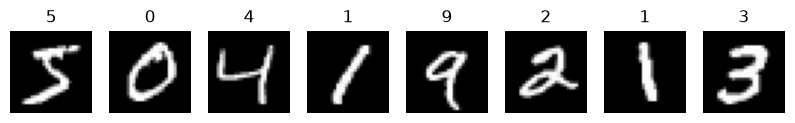

In [3]:
plt.figure(figsize=(10, 2))
for i in range(8):
    plt.subplot(1, 8, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(y_train[i])
    plt.axis("off")
plt.show()

## TwoLayerNetKeras class

hidden layer with relu, output layer with softmax. sgd optimizer and cross entropy loss.

In [4]:
class TwoLayerNetKeras:
    def __init__(self, input_size=784, hidden_size=50, output_size=10, lr=0.1):
        self.model = keras.Sequential([
            keras.Input(shape=(input_size,)),
            layers.Dense(hidden_size, activation="relu"),
            layers.Dense(output_size, activation="softmax"),
        ])
        self.model.compile(
            optimizer=keras.optimizers.SGD(learning_rate=lr),
            loss="categorical_crossentropy",
            metrics=["accuracy"],
        )

    def fit(self, x, t, x_val, t_val, epochs=15, batch_size=100):
        # print one short line per epoch instead of the keras progress bar
        def show(epoch, logs):
            print(f"epoch {epoch+1}  loss {logs['loss']:.4f}  acc {logs['accuracy']:.4f}  val acc {logs['val_accuracy']:.4f}")
        return self.model.fit(x, t, validation_data=(x_val, t_val),
                              epochs=epochs, batch_size=batch_size, verbose=0,
                              callbacks=[keras.callbacks.LambdaCallback(on_epoch_end=show)])

    def predict(self, x):
        return self.model.predict(x, batch_size=256, verbose=0)

    def accuracy(self, x, t):
        y = np.argmax(self.predict(x), axis=1)
        return np.mean(y == np.argmax(t, axis=1))

In [5]:
net = TwoLayerNetKeras(input_size=784, hidden_size=50, output_size=10, lr=0.1)
net.model.summary()

Model: "sequential"


_________________________________________________________________


 Layer (type)                Output Shape              Param #   


 dense (Dense)               (None, 50)                39250     


 dense_1 (Dense)             (None, 10)                510       


Total params: 39760 (155.31 KB)


Trainable params: 39760 (155.31 KB)


Non-trainable params: 0 (0.00 Byte)


_________________________________________________________________


## train

In [6]:
hist = net.fit(x_tr, t_tr, x_val, t_val, epochs=15, batch_size=100)

epoch 1  loss 0.4903  acc 0.8648  val acc 0.9206


epoch 2  loss 0.2733  acc 0.9211  val acc 0.9361


epoch 3  loss 0.2272  acc 0.9344  val acc 0.9441


epoch 4  loss 0.1953  acc 0.9434  val acc 0.9486


epoch 5  loss 0.1732  acc 0.9502  val acc 0.9535


epoch 6  loss 0.1559  acc 0.9554  val acc 0.9587


... (5 outputs left out)

epoch 12  loss 0.0967  acc 0.9726  val acc 0.9653


epoch 13  loss 0.0913  acc 0.9742  val acc 0.9678


epoch 14  loss 0.0854  acc 0.9758  val acc 0.9680


epoch 15  loss 0.0812  acc 0.9775  val acc 0.9688


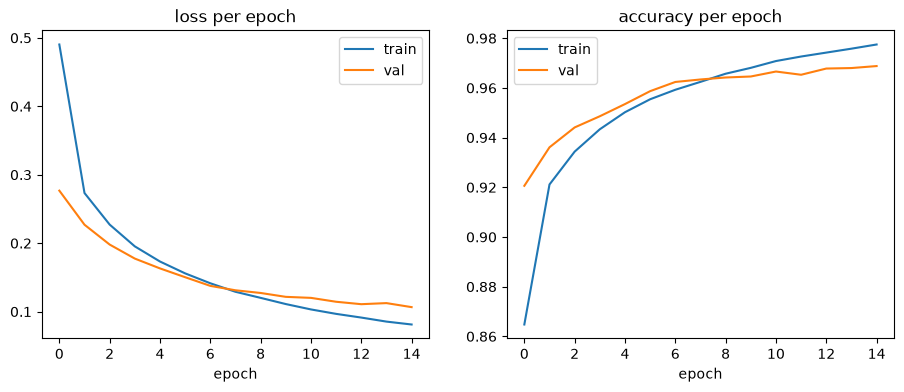

In [7]:
plt.figure(figsize=(11, 4))
plt.subplot(1, 2, 1)
plt.plot(hist.history["loss"], label="train")
plt.plot(hist.history["val_loss"], label="val")
plt.title("loss per epoch")
plt.xlabel("epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(hist.history["accuracy"], label="train")
plt.plot(hist.history["val_accuracy"], label="val")
plt.title("accuracy per epoch")
plt.xlabel("epoch")
plt.legend()
plt.show()

## test

now run it on the 10k test images it never saw.

In [8]:
test_loss, test_acc = net.model.evaluate(x_test, t_test, verbose=0)
train_acc = net.accuracy(x_tr, t_tr)
print(f"train acc: {train_acc:.4f}")
print(f"test loss: {test_loss:.4f}")
print(f"test acc:  {test_acc:.4f}")

train acc: 0.9802
test loss: 0.1028
test acc:  0.9698


check which digits it gets wrong the most

In [9]:
pred = np.argmax(net.predict(x_test), axis=1)
for d in range(10):
    mask = y_test == d
    print(f"digit {d}: {np.mean(pred[mask] == d):.3f}")

digit 0: 0.986
digit 1: 0.986
digit 2: 0.964
digit 3: 0.978
digit 4: 0.964
digit 5: 0.957
digit 6: 0.974
digit 7: 0.969
digit 8: 0.955
digit 9: 0.961


some test predictions (red = wrong)

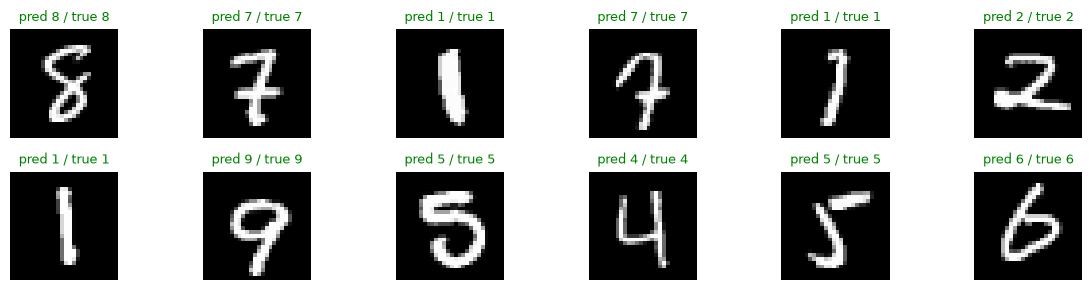

In [10]:
idx = np.random.choice(len(x_test), 12, replace=False)
plt.figure(figsize=(12, 3))
for k, i in enumerate(idx):
    plt.subplot(2, 6, k + 1)
    plt.imshow(X_test[i], cmap="gray")
    color = "green" if pred[i] == y_test[i] else "red"
    plt.title(f"pred {pred[i]} / true {y_test[i]}", color=color, fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.show()

## wrap up

the keras two layer net trains fine, val accuracy goes up every epoch and the test accuracy ends up close to the train accuracy, so it's not overfitting much. training and testing both work.